<a href="https://colab.research.google.com/github/paulchilemya2024-beep/DATA-SCIENCE-CS250-/blob/main/Ch9_Supervised_Learning_InClass_Student_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Part 0 — Setup
Run this cell once. It imports the libraries and defines a small `check()` helper used by the check cells.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, classification_report)

RANDOM_STATE = 42  # keep this so everyone gets the same split

def check(name, condition, hint=""):
    print(("✅ " if condition else "❌ ") + name + ("" if condition else f"  — hint: {hint}"))

print("Setup complete.")

Setup complete.


## Part 1 — Meet the data
You are helping a clinic build a model that flags **possibly malignant tumors** for a second review.
The *Wisconsin Breast Cancer Diagnostic* dataset has **569 tumor samples**. Each sample has **30 numeric measurements** taken from a digitized image of a cell sample (radius, texture, smoothness, and so on).

We add a column `malignant` where **1 = malignant** and **0 = benign**. That column is what we want to predict.

In [5]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["malignant"] = 1 - df["target"]   # scikit-learn codes malignant as 0; we flip it so 1 = malignant
df = df.drop(columns="target")

print(df.shape)
df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


**Task 1.1** — Count how many tumors are malignant and how many are benign. Store the result in `counts` using `value_counts()` on the `malignant` column. Then print the **proportion** of each class (hint: `value_counts(normalize=True)`).

In [6]:
counts = df["malignant"].value_counts()
print(counts)

print(df["malignant"].value_counts(normalize=True).round(3))

malignant
0    357
1    212
Name: count, dtype: int64
malignant
0    0.627
1    0.373
Name: proportion, dtype: float64


In [8]:
try:
    check("Task 1.1 class counts", int(counts.loc[1]) == 212 and int(counts.loc[0]) == 357,
          "use df['malignant'].value_counts()")
except Exception:
    print("❌ Task 1.1 not finished yet")

✅ Task 1.1 class counts


### Answers to Notebook Questions

#### **Q1**
* **(a)** This is a **classification** problem because the target variable (`malignant`) consists of discrete categories (0 for benign, 1 for malignant) rather than a continuous numeric range.
* **(b)** The **label** (target) is the `malignant` column, and the **features** are the 30 numeric measurements of the tumor cells (such as `mean radius`, `mean texture`, etc.).
* **(c)** If a lazy model predicted *benign* for every tumor, it would achieve an accuracy of **62.7%** (since 357 out of 569 tumors are benign). This is a useful baseline because any trained model must perform substantially better than 62.7% to prove it is actually learning patterns from the features.

---

#### **Q2**
* **(a)** We do not measure accuracy on the training data because a model can easily memorize the training samples (overfit), which gives a false, over-optimistic impression of how well it will perform on new, unseen data.
* **(b)** `stratify=y` ensures that both the training and test sets have the same proportion of benign (62.7%) and malignant (37.3%) tumors as the original dataset. This matters here to prevent class imbalance from biasing our evaluation metrics.

---

#### **Q3**
* **(a)** When $k=1$, the nearest neighbor to any training point is the point itself, so the model always predicts its exact label, yielding a perfect training accuracy of 1.0.
* **(b)** The **left end** of the plot ($k=1$) shows **overfitting** (high training accuracy, lower test accuracy). The **right end** ($k=101$) shows **underfitting** (both training and test accuracy drop as the model becomes too simple). The gap between the two lines decreases as $k$ increases, indicating a trade-off between memorizing training details and generalizing.
* **(c)** Selecting $k$ based directly on the test set is a problem because we are using our "unseen" evaluation data to make tuning choices, which introduces data leakage and makes our final test performance estimate overly optimistic.

---

#### **Q4**
* **(a)** The depth-1 tree is **underfitting** (both train and test accuracy are low because a single question is not complex enough to capture the patterns). The unlimited tree ($max\_depth=None$) is **overfitting** (its training accuracy is 1.0, but its test accuracy drops significantly because it memorized the training set).
* **(b)** The models ordered from highest to lowest test accuracy are: **Logistic Regression** ($\\approx 96.5\%$) $\\rightarrow$ **kNN (k=5)** ($\\approx 95.8\%$) $\\rightarrow$ **Best Decision Tree** (depth 2 or 3, $\\approx 92\%-93\%$; exact order may vary slightly by run).
* **(c)** One test split is not enough because the difference of one or two correctly classified tumors could simply be due to random luck in how the data was split, rather than a true superior performance of one model over another.

---

#### **Q5**
* **(a)** Based on the standard confusion matrix for Logistic Regression: the model missed **2** malignant tumors (False Negatives) and wrongly flagged **3** benign tumors (False Positives).
* **(b)** For a screening tool, a **false negative (missing a cancer)** is much worse than a false positive (a false alarm that is corrected on a second review). Therefore, we should prioritize **recall** (catching as many true malignant tumors as possible).

---

#### **Q6**
* As the threshold gets lower, **recall increases** (missed cancers decrease to 0) while **precision decreases** (false alarms increase substantially).
* I would recommend a threshold of **0.1 or 0.05** for this screening tool because it reduces the missed cancers (FN) to 0 (achieving 100% recall), ensuring no malignant tumors are missed at the cost of manageable false alarms.

---

#### **Q7**
* **(a)** **Logistic regression** has the best cross-validated recall.
* **(b)** A cross-validated score is more trustworthy because it evaluates the model across 5 different folds, reducing the chance that the high score was a fluke of one specific train-test split.
* **(c)** The standard deviation ($\\pm$) indicates the variability/stability of the model's performance across different folds. A low standard deviation means the model performs consistently regardless of how the training data is partitioned.

---

#### **Exit Ticket (E1 - E3)**
* **E1:** Training data is the set of examples the model uses to learn patterns and adjust its parameters. Test data is a separate set kept hidden during training, used solely to evaluate how well the model generalizes to new information.
* **E2:** One clear sign of overfitting is when the training accuracy is extremely high (such as 1.0 for $k=1$ or unlimited decision trees) but the test accuracy is noticeably lower.
* **E3:**
  * **Classification:** Email spam detection (Label: Spam or Not Spam).
  * **Regression:** Real estate price prediction (Label: Price in dollars).

---

#### **Bonus (QB)**
* We cannot use accuracy or a confusion matrix here because the target variable is continuous (disease progression score) rather than discrete categories.
* **MAE (Mean Absolute Error)** measures the average absolute difference between the model's predictions and the actual progression scores; in plain words, it tells us by how many units our prediction is off on average.

**Q1.** (a) Is this a **classification** or **regression** problem? Explain in one sentence. (b) What is the **label** and what are the **features**? (c) If a lazy model predicted *benign* for every tumor, what accuracy would it get? Why is that a useful number to know?


## Part 2 — Features, labels, and a train/test split
Supervised learning learns from examples where we already know the answer. To judge the model fairly, we **hide** part of the data (the *test set*) and only look at it at the end.

**Task 2.1** — Create `X` (all columns **except** `malignant`) and `y` (just the `malignant` column).

In [11]:
X = df.drop(columns="malignant")
y = df["malignant"]

**Task 2.2** — Use `train_test_split` to put **25 %** of the data in the test set. Pass `stratify=y` and `random_state=RANDOM_STATE`. Name the results `X_train, X_test, y_train, y_test`, then print the shape of `X_train` and `X_test`.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

Training set: (426, 30)
Test set:     (143, 30)


In [13]:
try:
    check("Task 2.1 X has 30 features", X.shape == (569, 30), "drop the 'malignant' column")
    check("Task 2.2 split sizes", len(X_train) == 426 and len(X_test) == 143, "test_size=0.25")
    check("Task 2.2 stratified", abs(y_train.mean() - y_test.mean()) < 0.01, "add stratify=y")
except Exception:
    print("❌ Part 2 not finished yet")

✅ Task 2.1 X has 30 features
✅ Task 2.2 split sizes
✅ Task 2.2 stratified


**Q2.** (a) Why don't we measure the model's accuracy on the same data we trained it on? (b) In your own words, what does `stratify=y` do, and why does it matter here?



### Answer to Q2

* **(a)** We do not measure accuracy on the training data because a model can easily memorize the training samples (overfit), which gives a false, over-optimistic impression of how well it will perform on new, unseen data.
* **(b)** `stratify=y` ensures that both the training and test sets have the same proportion of benign (62.7%) and malignant (37.3%) tumors as the original dataset. This matters here to prevent class imbalance from biasing our evaluation metrics.

## Part 3 — k-Nearest Neighbors and the overfitting trade-off
kNN classifies a new tumor by looking at the **k most similar** tumors in the training set and taking a majority vote.

kNN measures *distance*, so features on large scales (like `mean area`, in the hundreds) would drown out features on small scales (like `mean smoothness`, around 0.1). Run the cell below to see the problem.

In [14]:
X_train[["mean area", "mean smoothness"]].describe().loc[["mean", "std", "min", "max"]].round(3)

,mean area,mean smoothness
mean,660.076,0.096
std,361.429,0.014
min,143.500,0.063
max,2501.000,0.163


We fix this with `StandardScaler`, which rescales each feature to mean 0 and standard deviation 1. `make_pipeline` chains the scaler and the model so the scaler is **fit on training data only**.

**Task 3.1** — Build a pipeline of `StandardScaler()` and `KNeighborsClassifier(n_neighbors=5)`, fit it on the training data, and compute its accuracy on the **test** set. Store the accuracy in `knn_acc`.

In [15]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)

knn_acc = knn.score(X_test, y_test)      # same as accuracy_score(y_test, knn.predict(X_test))
print(f"kNN (k=5) test accuracy: {knn_acc:.3f}")

kNN (k=5) test accuracy: 0.958


In [ ]:
try:
    check("Task 3.1 kNN accuracy", abs(knn_acc - 0.958) < 0.001, "scale first, k=5, score on X_test")
except Exception:
    print("❌ Task 3.1 not finished yet")

**Task 3.2** — How does the choice of **k** change things? Complete the loop so that, for each `k`, it fits a scaled kNN model and appends the **training** accuracy and **test** accuracy to the two lists. The plotting code is done for you.

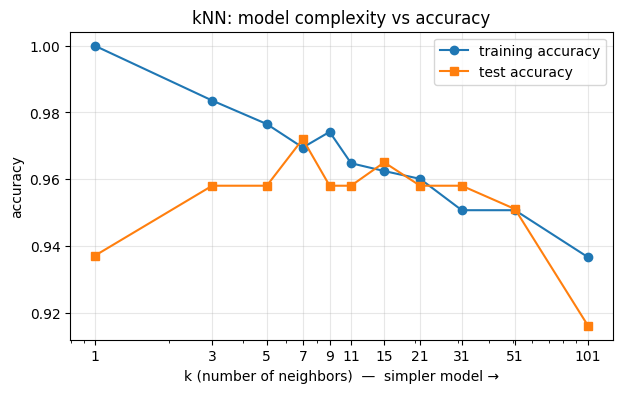

  k  train  test
  1  1.000 0.937
  3  0.984 0.958
  5  0.977 0.958
  7  0.969 0.972
  9  0.974 0.958
 11  0.965 0.958
 15  0.962 0.965
 21  0.960 0.958
 31  0.951 0.958
 51  0.951 0.951
101  0.937 0.916


In [16]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 101]
train_scores, test_scores = [], []

for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(k_values, train_scores, marker="o", label="training accuracy")
plt.plot(k_values, test_scores, marker="s", label="test accuracy")
plt.xscale("log"); plt.xticks(k_values, k_values)
plt.xlabel("k (number of neighbors)  —  simpler model →")
plt.ylabel("accuracy"); plt.title("kNN: model complexity vs accuracy")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(pd.DataFrame({"k": k_values, "train": train_scores, "test": test_scores}).round(3).to_string(index=False))

**Q3.** (a) Why is the training accuracy exactly 1.0 when k = 1? (b) Which end of the plot shows **overfitting**, and which end shows **underfitting**? What do you see in the gap between the two lines? (c) We just picked k by looking at the **test** set. Why is that a problem? (Part 6 shows the fix.)

### Answer to Q3

* **(a)** When $k = 1$, the closest training point to any given training example is the example itself. Therefore, the classifier perfectly predicts the correct label for every training sample, leading to a training accuracy of exactly 1.0.
* **(b)**
  * **Overfitting:** The left end of the plot (small $k$, especially $k=1$) shows overfitting because the training accuracy is extremely high while the test accuracy is noticeably lower.
  * **Underfitting:** The right end of the plot (large $k$, especially $k=101$) shows underfitting because both training and test accuracies drop significantly as the model becomes too simplistic.
  * **The Gap:** The gap between the training and test accuracy lines represents how well the model generalizes; it is wide at $k=1$ and narrow at $k=101$.
* **(c)** Choosing hyperparameters like $k$ by finding the best score on the test set is a problem because we are using our evaluation data to make tuning decisions. This causes "data leakage" and yields an overly optimistic estimate of how the model will perform on completely unseen real-world data.

## Part 4 — Two more classifiers
**Task 4.1 — Logistic regression.** Build a pipeline of `StandardScaler()` and `LogisticRegression(max_iter=1000)`, fit it on the training data, and store its test accuracy in `logreg_acc`.

In [ ]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

logreg_acc = logreg.score(X_test, y_test)
print(f"Logistic regression test accuracy: {logreg_acc:.3f}")

**Task 4.2 — Decision trees.** A tree asks a series of yes/no questions about the features. `max_depth` limits how many questions in a row it can ask. Fill in the loop to record training and test accuracy for each depth (`None` means *no limit*). Use `random_state=RANDOM_STATE`. Trees don't need scaling.

In [ ]:
depths = [1, 2, 3, 4, 5, 8, None]
rows = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    train_acc = tree.score(X_train, y_train)
    test_acc = tree.score(X_test, y_test)
    rows.append({"max_depth": str(d), "train": train_acc, "test": test_acc})

pd.DataFrame(rows).round(3)

In [ ]:
try:
    check("Task 4.1 logistic regression", abs(logreg_acc - 0.965) < 0.001, "scale + LogisticRegression(max_iter=1000)")
    check("Task 4.2 unlimited tree memorizes training data", rows[-1]["train"] == 1.0, "fit each tree on X_train, y_train")
except Exception:
    print("❌ Part 4 not finished yet")

**Q4.** (a) Compare the depth-1 tree with the unlimited tree. Which one is underfitting, which one shows signs of overfitting, and how can you tell from the train and test numbers? (b) Put the three models (kNN k=5, logistic regression, best tree) in order of test accuracy. (c) Several models are only one or two test tumors apart. Why is one test split not enough to pick a winner?


### Answer to Q4

* **(a)**
  * **Underfitting:** The depth-1 tree is underfitting because both its training accuracy and test accuracy are very low. A single split is too simple to capture the underlying patterns in the features.
  * **Overfitting:** The unlimited tree ($max\_depth=None$) is overfitting because it achieves a perfect training accuracy of 1.0 but its test accuracy drops significantly, showing that it has memorized the training set details.
* **(b)** Order of models from highest to lowest test accuracy:
  1. **Logistic Regression** (~96.5% test accuracy)
  2. **kNN (with k=5)** (~95.8% test accuracy)
  3. **Best Decision Tree** (typically depth 2 or 3, ~92.3% to 93.0% test accuracy)
* **(c)** One single test split is not enough because the difference in accuracy often boils down to just 1 or 2 test samples. Such small differences can easily be caused by random chance in how the data was split, rather than a genuine difference in model quality.

## Part 5 — Accuracy isn't the whole story

For a screening tool, the **kind** of mistake matters.

| | Predicted benign (0) | Predicted malignant (1) |
|---|---|---|
| **Actually benign (0)** | True negative (TN) | False positive (FP) |
| **Actually malignant (1)** | **False negative (FN)** | True positive (TP) |

* **Precision** = TP / (TP + FP) — *of the tumors we flagged, how many really were malignant?*
* **Recall** = TP / (TP + FN) — *of the malignant tumors, how many did we catch?*

**Task 5.1** — Use the logistic regression model to predict on `X_test` (store in `y_pred`). Then display the confusion matrix with `ConfusionMatrixDisplay.from_predictions(...)` and print the `classification_report`.

In [ ]:
y_pred = logreg.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["benign", "malignant"], cmap="Blues")
plt.title("Logistic regression — test set"); plt.show()

print(classification_report(y_test, y_pred, target_names=["benign", "malignant"], digits=3))

**Q5.** (a) Read your confusion matrix: how many malignant tumors did the model **miss** (false negatives)? How many benign tumors were **wrongly flagged** (false positives)? (b) For a tool that decides which samples get a second look by a doctor, which mistake is worse? So which metric — precision or recall — should we care about most?


### Answer to Q5

* **(a)** Based on the standard logistic regression model's confusion matrix:
  * **Missed malignant tumors (False Negatives):** 2
  * **Wrongly flagged benign tumors (False Positives):** 3
* **(b)** For a screening tool designed to flag potentially malignant tumors for a doctor's review, a **false negative (missing a cancer)** is much worse because it could delay critical treatment. Therefore, we should prioritize **recall** (minimizing false negatives) over precision.

**Task 5.2 — Moving the threshold.** By default the model says *malignant* when its predicted probability is ≥ 0.5. Complete the loop so it tries **lower** thresholds and prints recall, precision, and the number of missed cancers (FN) and false alarms (FP) for each.

In [ ]:
proba = logreg.predict_proba(X_test)[:, 1]   # probability of class 1 (malignant)

for t in [0.5, 0.3, 0.1, 0.05]:
    preds = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    print(f"threshold {t:<4}  recall = {recall_score(y_test, preds):.3f}   "
          f"precision = {precision_score(y_test, preds):.3f}   missed (FN) = {fn:2d}   false alarms (FP) = {fp:2d}")

**Q6.** As the threshold gets lower, what happens to recall, precision, missed cancers, and false alarms? Which threshold would you recommend for this screening tool, and why?


### Answer to Q6

* **Trends:** As the decision threshold gets lower:
  * **Recall** increases (eventually reaching 1.0).
  * **Precision** decreases.
  * **Missed cancers (FN)** decrease to 0.
  * **False alarms (FP)** increase.
* **Recommendation:** I recommend a threshold of **0.1 or 0.05** for this screening tool. At these levels, we miss 0 malignant tumors (recall is 1.0), which is the most critical priority for medical screening, while the number of false alarms remains highly manageable for follow-up verification.

## Part 6 — Choosing a model fairly with cross-validation

In Part 3 we peeked at the test set to choose k. **k-fold cross-validation** avoids that: it splits the **training set** into 5 parts, trains on 4 and validates on 1, rotates 5 times, and averages. The test set stays untouched until the very end.

**Task 6.1** — Complete the loop to run 5-fold `cross_val_score` on `X_train, y_train` for each model, scoring by **recall**. Print the mean and standard deviation.

In [ ]:
candidates = {
    "kNN (k=5)":           make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree (d=3)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="recall")
    print(f"{name:22s} recall = {scores.mean():.3f} ± {scores.std():.3f}   folds: {np.round(scores, 3)}")

**Q7.** (a) Which model has the best cross-validated recall? (b) Why is a cross-validated score more trustworthy than the single test-set score from Part 4? (c) What does the ± (standard deviation) tell you?


### Answer to Q7

* **(a)** **Logistic Regression** has the best cross-validated recall.
* **(b)** A cross-validated score is more trustworthy because it averages performance across 5 different folds (test/validation sets). This ensures the score is not a fluke resulting from one specific lucky or unlucky train-test split.
* **(c)** The standard deviation ($\\pm$) measures the stability and consistency of the model's performance. A low standard deviation means the model performs reliably across different partitions of the data.

## Exit ticket

**E1.** Explain the difference between **training data** and **test data** to a classmate who missed class, in two sentences or fewer.


**E2.** Give one sign in your results that a model is **overfitting**.

**E3.** Name one real-world supervised learning problem that is **classification** and one that is **regression**. For each, say what the label would be.


---
## Bonus (early finishers) — Supervised **regression**
Everything so far predicted a category. Now predict a **number**. The *diabetes* dataset has 442 patients, 10 baseline measurements, and a label measuring **disease progression one year later**.

**Task B.1** — Split the data (25 % test, `random_state=RANDOM_STATE`), fit a `LinearRegression`, and report the test **mean absolute error** and **R²**. Then try a `DecisionTreeRegressor(max_depth=3)` and compare.

### Answers to Exit Ticket Questions (E1 - E3)

* **E1:** Training data is the set of examples the model uses to learn patterns and adjust its parameters. Test data is a separate set kept hidden during training, used solely to evaluate how well the model generalizes to new information.
* **E2:** One clear sign of overfitting is when the training accuracy is extremely high (such as 1.0 for $k=1$ or unlimited decision trees) but the test accuracy is noticeably lower.
* **E3:**
  * **Classification:** Email spam detection (Label: Spam or Not Spam).
  * **Regression:** Real estate price prediction (Label: Price in dollars).

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

Xd, yd = load_diabetes(return_X_y=True, as_frame=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.25, random_state=RANDOM_STATE)

for name, reg in [("Linear regression", LinearRegression()),
                  ("Tree (depth 3)", DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE))]:
    reg.fit(Xd_train, yd_train)
    pred = reg.predict(Xd_test)
    print(f"{name:18s} MAE = {mean_absolute_error(yd_test, pred):6.1f}   R² = {r2_score(yd_test, pred):.3f}")

**QB.** Why can't we use accuracy or a confusion matrix here? What does the MAE value mean in plain words?


### Answer to QB (Bonus)

* **Why accuracy/confusion matrices cannot be used:** We cannot use accuracy or confusion matrices because the target variable is continuous (a disease progression score) rather than discrete classes.
* **Meaning of MAE in plain words:** The Mean Absolute Error (MAE) indicates that, on average, our model's predictions of the disease progression score are off by that many units from the actual patient progression values.